# Case Study 2 - T-cell component selection

### Inputs and outputs

| Input | 12 PCW / 17 PCW file |
|---|---|
| Binarized STREAM observations | `../Results/Binarization_outputs/{week}/stream_state_binarization.csv` |
| STREAM graph | `../Results/STREAM_outputs/{week}/tables/tree_nodes.csv` and `tree_edges.csv` | 
| STREAM root | `../Results/STREAM_outputs/{week}/run_summary.json` | 
| Cell-type composition | `../Results/STREAM_outputs/{week}/tables/state_cell_type_counts.csv` | 
| STREAM variable genes (optional) | `../Results/STREAM_outputs/{week}/tables/selected_stream_variable_genes.csv` |
| Human prior network | `../Data/dorothea_human_ABC_TF.sif` | 
| Human MSigDB | `../Data/msigdb.v2025.1.Hs.symbols.gmt` | 

Two independent results folders: `../Results/Component_selection_Tcell_manual/12w/` and `17w/`. Execute with the same project working directory used by your other notebooks.

## Data preprocessing

### 1. Import observations from single-cell binarization

The previous R Markdown notebook already performed binarization and aggregation. 

In [21]:
from pathlib import Path
from collections import defaultdict
from itertools import combinations
import json
import re
import shutil
import urllib.request

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('../Data')
STREAM_DIR = Path('../Results/STREAM_outputs')
BIN_DIR = Path('../Results/Binarization_outputs')
OUTPUT_DIR = Path('../Results/Component_selection_Tcell_manual')
WEEKS = ('12w', '17w')

# True reproduces Chevalier's use of STREAM-selected variable genes.
RESTRICT_TO_STREAM_VARIABLE = False

# Same seed-guided candidate-network idea as the original Nestorowa notebook.
SEED_TOP_N = 25
MIN_MATCHING_SETS = 1
NEIGHBOR_HOPS = 1
INCLUDE_SHORT_BRIDGES = True
MAX_BRIDGE_EDGES = 3
MAX_CANDIDATE_GENES = 150
MAXCLAUSE = 8

# S4 is a required fixed point in both models; no optional switch.
RUN_OPTIMIZATION_IN_NOTEBOOK = True
OPTIMIZATION_TIME_LIMIT_SECONDS = 14400

for directory in (DATA_DIR, OUTPUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print('Outputs:', OUTPUT_DIR.resolve())


Outputs: /home/eren/Eren_run/Case_study_2/Results/Component_selection_Tcell_manual


In [2]:
def read_observations(week):
    path = BIN_DIR / week / 'stream_state_binarization.csv'
    if not path.is_file():
        raise FileNotFoundError(f'{week}: missing {path}')
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    if 'State' not in df.columns:
        raise ValueError(f'{path}: expected State column')
    if df['State'].duplicated().any():
        raise ValueError(f'{week}: duplicate STREAM state names')
    df = df.set_index('State')
    if df.columns.duplicated().any():
        raise ValueError(f'{week}: duplicate gene names')
    df = df.apply(lambda col: col.str.strip().str.upper())
    allowed = {'0', '1', 'ND', 'NA', 'NAN', ''}
    found = set(df.to_numpy().ravel())
    if found - allowed:
        raise ValueError(f'{week}: invalid binary calls: {sorted(found - allowed)}')
    df = df.replace({'ND': np.nan, 'NA': np.nan, 'NAN': np.nan, '': np.nan})
    df = df.apply(pd.to_numeric)
    return df

observed_12 = read_observations('12w')
observed_17 = read_observations('17w')
print('12 PCW:', observed_12.shape)
print('17 PCW:', observed_17.shape)
display(observed_12.iloc[:5, :8])
display(observed_17.iloc[:5, :8])

12 PCW: (8, 33694)
17 PCW: (6, 33694)


,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2
State,,,,,,,,
S0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
S1,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
S2,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
S3,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
S4,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN


,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2
State,,,,,,,,
S0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
S1,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
S2,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
S3,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN
S4,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN


### 2. Standardize human gene names

In [3]:
def standardize_human_symbols(df):
    cols = [str(gene).strip().upper() for gene in df.columns]
    groups = defaultdict(list)
    for position, gene in enumerate(cols):
        groups[gene].append(position)
    clean = {}
    for gene, positions in groups.items():
        sub = df.iloc[:, positions]
        if len(positions) == 1:
            clean[gene] = sub.iloc[:, 0]
        else:
            agree = sub.nunique(axis=1, dropna=True) <= 1
            clean[gene] = sub.bfill(axis=1).iloc[:, 0].where(agree)
    return pd.DataFrame(clean, index=df.index)

observed_12 = standardize_human_symbols(observed_12)
observed_17 = standardize_human_symbols(observed_17)

# Optional: restrict each week to its own STREAM-variable genes.
def restrict_variable_genes(week, df):
    if not RESTRICT_TO_STREAM_VARIABLE:
        return df
    path = STREAM_DIR / week / 'tables' / 'selected_stream_variable_genes.csv'
    if not path.is_file():
        raise FileNotFoundError(f'{week}: missing {path}')
    genes_table = pd.read_csv(path)
    if 'gene' not in genes_table.columns:
        raise ValueError(f'{path}: expected gene column')
    eligible = set(genes_table['gene'].astype(str).str.strip().str.upper())
    result = df.loc[:, df.columns.isin(eligible)]
    if result.shape[1] == 0:
        raise ValueError(f'{week}: no variable genes match the binarization')
    return result

observed_12 = restrict_variable_genes('12w', observed_12)
observed_17 = restrict_variable_genes('17w', observed_17)
print('Gene universes:', observed_12.shape[1], '(12w);', observed_17.shape[1], '(17w)')

Gene universes: 33694 (12w); 33694 (17w)


### 3. Inspect the original STREAM states and topology

This step verifies that the figures, binarization, and node names are consistent.

In [4]:
# Edges below were transcribed and reviewed against the two supplied subway plots.
EXPECTED_EDGES = {
    '12w': {frozenset(p) for p in [
        ('S3', 'S0'), ('S3', 'S6'), ('S3', 'S7'), ('S0', 'S1'),
        ('S0', 'S2'), ('S2', 'S4'), ('S2', 'S5')
    ]},
    '17w': {frozenset(p) for p in [
        ('S3', 'S0'), ('S3', 'S4'), ('S3', 'S5'),
        ('S0', 'S1'), ('S0', 'S2')
    ]},
}

def check_stream(week, df):
    tables = STREAM_DIR / week / 'tables'
    with (STREAM_DIR / week / 'run_summary.json').open(encoding='utf-8') as f:
        summary = json.load(f)
    nodes = pd.read_csv(tables / 'tree_nodes.csv', dtype=str)
    edges = pd.read_csv(tables / 'tree_edges.csv', dtype=str)
    counts = pd.read_csv(tables / 'state_cell_type_counts.csv', index_col=0)
    root = str(summary['root'])
    if root != 'S3':
        raise ValueError(f'{week}: expected the supplied root S3, got {root}')
    states = set(nodes['state'].astype(str))
    if states != set(df.index):
        raise ValueError(f'{week}: state labels differ between STREAM and binarization')
    actual = {frozenset((str(a), str(b)))
              for a, b in zip(edges['from_state'], edges['to_state'])}
    if actual != EXPECTED_EDGES[week]:
        raise ValueError(f'{week}: fitted topology differs from the supplied plot; '
                         'review manual BoNesis constraints before running')
    counts.index = counts.index.astype(str)
    return counts

counts_12 = check_stream('12w', observed_12)
counts_17 = check_stream('17w', observed_17)
print('Both STREAM roots and topologies agree with the supplied plots.')
display(counts_12)
display(counts_17)

Both STREAM roots and topologies agree with the supplied plots.


,CD4+T,CD8+T,DN(P),DN(Q),DN(early),DP(P),DP(Q),αβT(entry)
nearest_state,,,,,,,,
S0,0,0,9,99,0,3,14,0
S1,0,0,0,32,0,0,1,0
S2,42,14,0,0,1,3,103,69
S3,1,1,281,156,94,263,117,15
S4,83,71,0,0,0,2,0,59
S5,0,0,0,2,0,0,19,1
S6,0,0,0,0,0,0,34,37
S7,0,0,0,1,0,20,3,0


,CD4+T,CD8+T,DN(P),DN(Q),DN(early),DP(P),DP(Q),αβT(entry)
nearest_state,,,,,,,,
S0,0,0,3,3,1,139,23,0
S1,0,0,4,10,0,22,103,5
S2,0,0,1,0,0,9,4,0
S3,126,137,33,51,4,226,177,70
S4,141,132,0,0,0,0,0,85
S5,0,0,0,3,0,2,91,45


### What the signed influence graph means

A human DoRothEA SIF row has `regulator   sign   target`, where `+1` permits activation and `-1` permits inhibition. These are **allowed prior interactions**, not inferred Boolean functions. Chevalier et al. combine this *structural prior* with the *dynamical constraints* specified later.

### 4. Get the human DoRothEA A–C signed interaction graph

In [5]:
HUMAN_SIF = DATA_DIR / 'dorothea_human_ABC_TF.sif'
DOROTHEA_URL = ('https://omnipathdb.org/interactions?datasets=dorothea&'
                'organisms=9606&genesymbols=yes&dorothea_levels=A,B,C')

def load_or_download_dorothea():
    if not HUMAN_SIF.is_file():
        raw_path = DATA_DIR / 'dorothea_human_ABC_omnipath_raw.tsv'
        request = urllib.request.Request(DOROTHEA_URL, headers={'User-Agent':'Mozilla/5.0'})
        with urllib.request.urlopen(request, timeout=180) as response:
            raw_path.write_bytes(response.read())
        raw = pd.read_csv(raw_path, sep='\t', low_memory=False)
        sc = next((c for c in ('source_genesymbol', 'source_genesymb') if c in raw), None)
        tc = next((c for c in ('target_genesymbol', 'target_genesymb') if c in raw), None)
        if sc is None or tc is None:
            raise ValueError('OmniPath did not provide human gene symbols')
        if 'dorothea_level' in raw:
            raw = raw.loc[raw['dorothea_level'].isin(['A', 'B', 'C'])]
        stim = next((c for c in ('is_stimulation','consensus_stimulation') if c in raw), None)
        inhib = next((c for c in ('is_inhibition','consensus_inhibition') if c in raw), None)
        if stim is None or inhib is None:
            raise ValueError('No signed stimulation/inhibition columns; supply a signed SIF')
        is_true = lambda s: s.astype(str).str.lower().isin(['1','1.0','true','t','yes'])
        plus, minus = is_true(raw[stim]), is_true(raw[inhib])
        sure = plus.ne(minus)  # Drop unsigned and ambiguous rows.
        data = pd.DataFrame({
            'source': raw.loc[sure, sc].astype(str).str.upper().str.strip(),
            'sign': np.where(plus.loc[sure], '1', '-1'),
            'target': raw.loc[sure, tc].astype(str).str.upper().str.strip(),
        }).drop_duplicates()
        data = data.loc[~data.source.isin(['', 'NAN']) &
                        ~data.target.isin(['', 'NAN'])]
        conflicts = data.groupby(['source','target']).sign.nunique()
        ambiguous = set(conflicts[conflicts > 1].index)
        data = data.loc[[pair not in ambiguous for pair in zip(data.source, data.target)]]
        if data.empty:
            raise ValueError('No unambiguous regulations remained')
        data.to_csv(HUMAN_SIF, sep='\t', index=False, header=False)
    sif = pd.read_csv(HUMAN_SIF, sep='\t', header=None,
                      names=['source','sign','target'], dtype=str, comment='#')
    sif = sif.dropna().drop_duplicates()
    sif['source'] = sif.source.str.strip().str.upper()
    sif['target'] = sif.target.str.strip().str.upper()
    if not sif.sign.isin(['1','-1']).all():
        raise ValueError('Expected signed SIF: source TAB 1/-1 TAB target')
    return sif

sif = load_or_download_dorothea()
full_graph = nx.DiGraph()
full_graph.add_edges_from(zip(sif.source, sif.target))
print('Human prior network:', len(full_graph), 'genes;', len(sif), 'signed regulations')

Human prior network: 3369 genes; 7283 signed regulations


### 5. Download the complete **human** MSigDB

In [6]:
MSIGDB_RELEASE = '2025.1.Hs'
MSIGDB_GMT = DATA_DIR / f'msigdb.v{MSIGDB_RELEASE}.symbols.gmt'
MSIGDB_URL = (f'https://data.broadinstitute.org/gsea-msigdb/msigdb/release/'
              f'{MSIGDB_RELEASE}/{MSIGDB_GMT.name}')
MSIGDB_PART = Path(str(MSIGDB_GMT) + '.part')
MSIGDB_CHUNK_SIZE = 2 * 1024 * 1024  # 2 MB requests avoid large single transfers.
MSIGDB_MIN_BYTES = 15 * 1024 * 1024  # Detect the previously truncated 5 MB file.


def check_gmt_file(path):
    """Check that the downloaded file looks like a complete tab-separated GMT."""
    if not path.exists() or path.stat().st_size < MSIGDB_MIN_BYTES:
        return False
    with path.open('rb') as f:
        first_line = f.readline()
        f.seek(-1, 2)
        last_byte = f.read(1)
    return first_line.count(b'\t') >= 2 and last_byte == b'\n'


def download_msigdb_gmt():
    """Download MSigDB in small, resumable HTTP range requests."""
    headers = {'User-Agent': 'Mozilla/5.0', 'Accept-Encoding': 'identity'}

    # Ask the server for one byte to find the total file size.
    probe = urllib.request.Request(
        MSIGDB_URL, headers={**headers, 'Range': 'bytes=0-0'})
    with urllib.request.urlopen(probe, timeout=90) as response:
        content_range = response.headers.get('Content-Range', '')
        status = response.status
        response.read(1)

    match = re.fullmatch(r'bytes 0-0/(\d+)', content_range)
    if status != 206 or match is None:
        raise RuntimeError(
            'MSigDB server did not accept partial downloads. Download the GMT '
            'through a browser and save it here: ' + str(MSIGDB_GMT.resolve()))
    total_size = int(match.group(1))

    # Continue a previously interrupted download, if present.
    if MSIGDB_PART.exists() and MSIGDB_PART.stat().st_size > total_size:
        MSIGDB_PART.unlink()
    start = MSIGDB_PART.stat().st_size if MSIGDB_PART.exists() else 0
    print(f'Downloading MSigDB: {start / 1e6:.1f} / {total_size / 1e6:.1f} MB')

    while start < total_size:
        stop = min(start + MSIGDB_CHUNK_SIZE, total_size) - 1
        expected_range = f'bytes {start}-{stop}/{total_size}'
        for attempt in range(3):
            try:
                request = urllib.request.Request(
                    MSIGDB_URL,
                    headers={**headers, 'Range': f'bytes={start}-{stop}'})
                with urllib.request.urlopen(request, timeout=90) as response:
                    if response.status != 206 or response.headers.get('Content-Range') != expected_range:
                        raise RuntimeError('Server returned an unexpected byte range')
                    data = response.read(stop - start + 1)
                if len(data) != stop - start + 1:
                    raise RuntimeError('Downloaded chunk is incomplete')
                with MSIGDB_PART.open('ab') as f:
                    f.write(data)
                break
            except Exception:
                if attempt == 2:
                    raise RuntimeError(
                        f'MSigDB transfer interrupted at byte {start}. '
                        'Rerun this cell to resume, or download the GMT manually.')
        start = stop + 1
        print(f'  {start / 1e6:.1f} / {total_size / 1e6:.1f} MB', end='\r')

    if MSIGDB_PART.stat().st_size != total_size or not check_gmt_file(MSIGDB_PART):
        raise RuntimeError('MSigDB GMT is incomplete or invalid; no file was accepted.')
    MSIGDB_PART.replace(MSIGDB_GMT)
    print('\nDownload complete.')


if not check_gmt_file(MSIGDB_GMT):
    download_msigdb_gmt()

print('MSigDB:', MSIGDB_GMT, f'({MSIGDB_GMT.stat().st_size / 1e6:.1f} MB)')


MSigDB: ../Data/msigdb.v2025.1.Hs.symbols.gmt (30.1 MB)


### 6. Find T-cell differentiation gene sets across MSigDB collections

Restrict names to **thymocyte development, T-cell differentiation, lineage commitment, maturation, selection, and TCR rearrangement**. Broad hematopoiesis, generic immune activation, and NK/γδ-specific pathways are not automatically included. Park et al. discuss `ST18` (early DN), `AQP3` (DP), `TOX2` (DP-to-SP), `RAG1/RAG2`, `PTCRA`, `CCR9`, `CD4`, and `CD8A/CD8B`.

In [7]:
SEARCH_PATTERNS = [
    r'T_CELL_DIFFERENTIATION', r'THYMOCYTE_DIFFERENTIATION',
    r'T_CELL_LINEAGE_COMMITMENT', r'T_CELL_SELECTION',
    r'THYMOCYTE_SELECTION', r'T_CELL_MATURATION',
    r'THYMOCYTE_MATURATION', r'T_CELL_RECEPTOR.*RECOMBINATION',
    r'T_CELL_RECEPTOR.*REARRANGEMENT',
]
PARK_MARKERS = {
    'ST18','AQP3','TOX2','CD4','CD8A','CD8B',
    'CCR9','CDK1','RAG1','RAG2','PTCRA'
}

matching_sets, gene_to_sets = {}, defaultdict(set)
with MSIGDB_GMT.open(encoding='utf-8') as f:
    for line in f:
        fields = line.rstrip('\n\r').split('\t')
        if len(fields) < 3:
            continue
        name = fields[0].upper()
        if not any(re.search(pat, name) for pat in SEARCH_PATTERNS):
            continue
        genes = {g.strip().upper() for g in fields[2:] if g.strip()}
        matching_sets[name] = genes
        for gene in genes:
            gene_to_sets[gene].add(name)
if not matching_sets:
    raise ValueError('No differentiation gene sets found; review SEARCH_PATTERNS')
matched_sets_df = pd.DataFrame([
    {'gene_set': name, 'n_genes':len(genes)} for name, genes in matching_sets.items()
]).sort_values('gene_set')
gene_membership_df = pd.DataFrame([
    {'gene':gene, 'n_matching_sets':len(sets),
     'matching_sets':'; '.join(sorted(sets))}
    for gene, sets in gene_to_sets.items()
]).sort_values(['n_matching_sets','gene'],ascending=[False,True])
matched_sets_df.to_csv(OUTPUT_DIR/'human_tcell_matched_gene_sets.csv',index=False)
gene_membership_df.to_csv(OUTPUT_DIR/'human_tcell_gene_memberships.csv',index=False)
print(len(matching_sets), 'matched gene sets;', len(gene_to_sets), 'unique member genes')
display(matched_sets_df.head(25))

54 matched gene sets; 706 unique member genes


,gene_set,n_genes
1,GOBP_ALPHA_BETA_T_CELL_DIFFERENTIATION,140
2,GOBP_BROWN_FAT_CELL_DIFFERENTIATION,53
3,GOBP_CARDIAC_FIBROBLAST_CELL_DIFFERENTIATION,5
4,GOBP_CARDIAC_NEURAL_CREST_CELL_DIFFERENTIATION...,16
5,GOBP_CD4_POSITIVE_ALPHA_BETA_T_CELL_DIFFERENTI...,108
6,GOBP_CD4_POSITIVE_CD25_POSITIVE_ALPHA_BETA_REG...,11
7,GOBP_CD4_POSITIVE_OR_CD8_POSITIVE_ALPHA_BETA_T...,36
8,GOBP_CD8_POSITIVE_ALPHA_BETA_T_CELL_DIFFERENTI...,15
9,GOBP_CHORIONIC_TROPHOBLAST_CELL_DIFFERENTIATION,7
10,GOBP_FAT_CELL_DIFFERENTIATION,260


### 7. Select T-cell biological seeds represented in DoRothEA

The two weeks receive **separate seed sets** because their measured, binarized gene universes differ. As in the Nestorowa notebook, seeds are ranked by gene-set membership and network connectivity. We additionally retain relevant Park marker genes **only if they occur in the measured regulatory prior**.

In [8]:
def rank_week_seeds(week, df):
    measured = set(df.columns) & set(full_graph.nodes())
    rows = []
    for gene in sorted(measured):
        rows.append({
            'gene': gene,
            'n_matching_sets': len(gene_to_sets.get(gene, set())),
            'degree': full_graph.degree(gene),
            'determined_states': int(df[gene].notna().sum()),
            'park_marker': gene in PARK_MARKERS,
        })
    scores = pd.DataFrame(rows)
    if scores.empty:
        raise ValueError(f'{week}: no overlap between observations and DoRothEA')
    eligible = scores[(scores.n_matching_sets >= MIN_MATCHING_SETS) &
                      (scores.determined_states > 0)].copy()
    top = eligible.sort_values(['n_matching_sets','degree','gene'],
                               ascending=[False,False,True]).head(SEED_TOP_N)
    markers = scores[(scores.park_marker) & (scores.determined_states > 0)]
    seeds = set(top.gene) | set(markers.gene)
    if not seeds:
        raise ValueError(f'{week}: no matching biological seeds')
    scores['chosen_seed'] = scores.gene.isin(seeds)
    scores.to_csv(OUTPUT_DIR/f'{week}_seed_ranking.csv', index=False)
    return scores, seeds

scores_12, seeds_12 = rank_week_seeds('12w', observed_12)
scores_17, seeds_17 = rank_week_seeds('17w', observed_17)
print('12 PCW seeds:', len(seeds_12), '; 17 PCW seeds:', len(seeds_17))
display(scores_12.query('chosen_seed').head(15))
display(scores_17.query('chosen_seed').head(15))

12 PCW seeds: 32 ; 17 PCW seeds: 31


,gene,n_matching_sets,degree,determined_states,park_marker,chosen_seed
56,ADA,7,7,8,False,True
190,AQP3,0,1,8,True,True
332,BRD2,12,1,8,False,True
333,BRD4,12,3,8,False,True
440,CD28,6,2,8,False,True
446,CD4,2,3,8,True,True
457,CD69,13,3,8,False,True
459,CD74,8,4,8,False,True
466,CD8A,1,3,8,True,True
467,CD8B,0,2,7,True,True


,gene,n_matching_sets,degree,determined_states,park_marker,chosen_seed
56,ADA,7,7,6,False,True
190,AQP3,0,1,6,True,True
230,ATF2,5,30,6,False,True
332,BRD2,12,1,6,False,True
333,BRD4,12,3,6,False,True
426,CCR7,5,2,6,False,True
440,CD28,6,2,6,False,True
446,CD4,2,3,6,True,True
457,CD69,13,3,6,False,True
459,CD74,8,4,6,False,True


### 8. Expand the biological seeds into a signed prior network

Following your Nestorowa workflow, retain direct regulatory neighbors and short connecting paths. 

In [9]:
def prepare_candidate_graph(week, df, scores, seeds):
    measured = set(df.columns) & set(full_graph.nodes())
    week_graph = full_graph.subgraph(measured).copy()
    seed_pool, frontier = set(seeds), set(seeds)
    for _ in range(NEIGHBOR_HOPS):
        new = set()
        for gene in frontier:
            new.update(week_graph.predecessors(gene))
            new.update(week_graph.successors(gene))
        frontier = new - seed_pool
        seed_pool.update(frontier)

    bridges = set()
    if INCLUDE_SHORT_BRIDGES:
        weak = week_graph.to_undirected()
        for gene_a, gene_b in combinations(sorted(seeds), 2):
            try:
                path = nx.shortest_path(weak, gene_a, gene_b)
                if len(path)-1 <= MAX_BRIDGE_EDGES:
                    bridges.update(path)
            except nx.NetworkXNoPath:
                continue

    required = seeds | bridges
    if len(required) > MAX_CANDIDATE_GENES:
        raise ValueError(f'{week}: {len(required)} required genes exceed '
                         f'MAX_CANDIDATE_GENES={MAX_CANDIDATE_GENES}')
    def priority(gene):
        contacts = sum(week_graph.has_edge(gene, s) or week_graph.has_edge(s, gene)
                       for s in seeds)
        return (-contacts, -week_graph.degree(gene), gene)
    remaining = seed_pool - required
    slots = MAX_CANDIDATE_GENES - len(required)
    chosen = required | set(sorted(remaining, key=priority)[:slots])
    candidate = week_graph.subgraph(chosen).copy()
    # Preserve only connected components containing a biological seed.
    keep = set()
    for component in nx.weakly_connected_components(candidate):
        if component & seeds:
            keep.update(component)
    candidate = candidate.subgraph(keep).copy()
    signed = sif[sif.source.isin(candidate.nodes()) &
                 sif.target.isin(candidate.nodes())].copy()
    if signed.empty:
        raise ValueError(f'{week}: no signed edges in candidate network')
    final_genes = set(signed.source) | set(signed.target)
    out = OUTPUT_DIR / week
    out.mkdir(parents=True, exist_ok=True)
    signed_path = out/'candidate_human_DoRothEA.sif'
    signed.to_csv(signed_path, sep='\t', header=False, index=False)
    obs = {state:{gene:int(value) for gene,value in row.items()
                  if gene in final_genes and pd.notna(value)}
           for state, row in df.iterrows()}
    if any(not calls for calls in obs.values()):
        raise ValueError(f'{week}: at least one state has no determined candidate genes')
    pd.DataFrame.from_dict(obs, orient='index').to_csv(
        out/'candidate_state_observations.csv', index_label='State', na_rep='ND')
    pd.DataFrame({'gene':sorted(seeds)}).to_csv(out/'biological_seeds.csv', index=False)
    pd.DataFrame({'gene':sorted(final_genes)}).to_csv(out/'candidate_genes.csv', index=False)
    return {'week':week, 'observations':obs, 'sif_path':signed_path,
            'n_genes':len(final_genes), 'n_edges':len(signed),
            'output':out, 'seeds':seeds}

### 8.1. Candidate network — 12 PCW

In [10]:
ctx12 = prepare_candidate_graph('12w', observed_12, scores_12, seeds_12)
print('12 PCW:', ctx12['n_genes'], 'genes;', ctx12['n_edges'], 'signed regulations')

12 PCW: 150 genes; 843 signed regulations


### 8.2. Candidate network — 17 PCW

In [11]:
ctx17 = prepare_candidate_graph('17w', observed_17, scores_17, seeds_17)
print('17 PCW:', ctx17['n_genes'], 'genes;', ctx17['n_edges'], 'signed regulations')

17 PCW: 150 genes; 863 signed regulations


### 8.3. Candidate network reduction

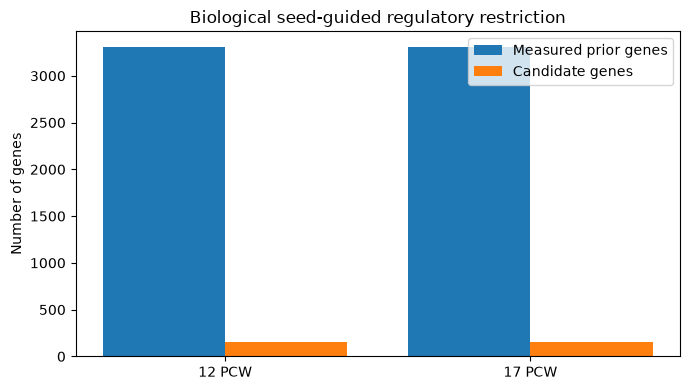

In [12]:
fig, ax = plt.subplots(figsize=(7,4))
labels = ['12 PCW','17 PCW']
measured = [len(set(obs.columns)&set(full_graph.nodes())) for obs in (observed_12, observed_17)]
selected = [ctx12['n_genes'],ctx17['n_genes']]
xx = np.arange(2)
ax.bar(xx-.2, measured, width=.4, label='Measured prior genes')
ax.bar(xx+.2, selected, width=.4, label='Candidate genes')
ax.set_xticks(xx, labels)
ax.set_ylabel('Number of genes')
ax.set_title('Biological seed-guided regulatory restriction')
ax.legend()
plt.tight_layout()
plt.show()

### 9. Initialize two independent BoNesis problems

In [13]:
import bonesis

def make_problem(ctx):
    graph = bonesis.InfluenceGraph.from_sif(
        str(ctx['sif_path']), maxclause=MAXCLAUSE,
        allow_skipping_nodes=True, canonic=False)
    measured_genes = set(graph.nodes())
    obs = {state:{g:v for g,v in calls.items() if g in measured_genes}
           for state,calls in ctx['observations'].items()}
    return bonesis.BoNesis(graph, obs)

bo12 = make_problem(ctx12)
bo17 = make_problem(ctx17)
print('BoNesis domains created independently.')

ipylab module is not installed, menus and toolbar are disabled.


BoNesis domains created independently.


## Dynamics — 12 PCW

The constraints in the following cells were **manually selected** from this exact STREAM plot, with Park et al.'s maturation order as the biological criterion.

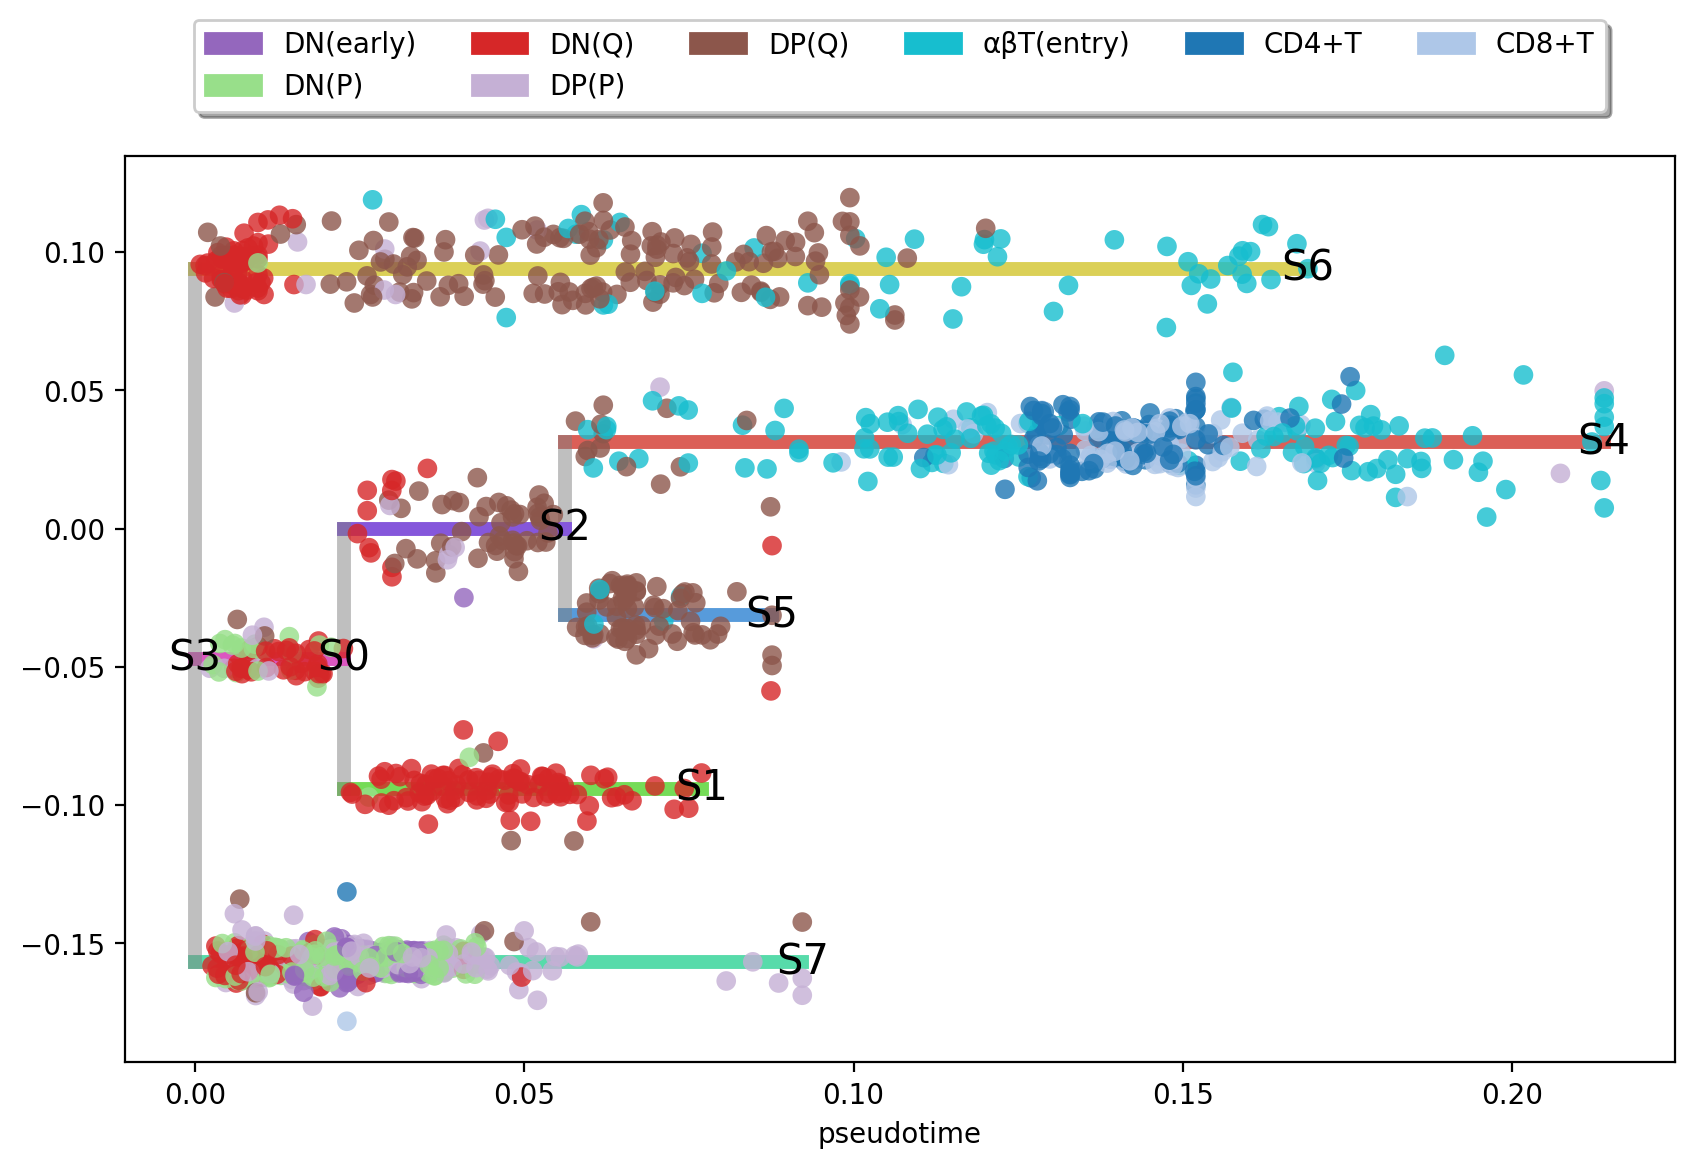

The S3 → S0 → S2 → S4 route is the strongest graph-supported *approximation* to progression from immature DN-associated states through DP-associated states toward an αβT(entry)/SP-enriched region. S3 → S6 also reaches a DP(Q)/αβT(entry)-enriched region without clear mature SP enrichment. S0 → S1 (DN(Q)-rich) and S3 → S7 (DN(P)/DP(P)-rich) may represent additional **immature/intermediate populations**, so they can be reachable without being stable endpoints. S2 → S5 does not show a compelling new developmental stage beyond a DP(Q)-rich population, so we do not enforce that edge.

### 10.1. Fixed points — 12 PCW

In [15]:
# Require the 12 PCW mature-SP-enriched S4 observation to be stable.
s4_target_12 = bo12.fixed(~bo12.obs('S4'))

### 10.2. Positive reachability — 12 PCW

In [16]:
# immature DN-associated → DP-associated → later entry/SP region.
~bo12.obs('S3') >= ~bo12.obs('S0')
~bo12.obs('S0') >= ~bo12.obs('S2')
~bo12.obs('S2') >= s4_target_12

# Plausible partial progression to DP(Q)/αβT(entry), without calling it terminal.
~bo12.obs('S3') >= ~bo12.obs('S6')

# Immature/proliferative subpopulations: reachable, but not fixed fates.
~bo12.obs('S0') >= ~bo12.obs('S1')
~bo12.obs('S3') >= ~bo12.obs('S7')

reach('<bonesis.language.ManagedIface.__init__.<locals>.managed.<locals>.Managed object at 0x7c47497d2990>', '<bonesis.language.ManagedIface.__init__.<locals>.managed.<locals>.Managed object at 0x7c475258f690>')

### 10.3. Original optimization objectives — 12 PCW

In [17]:
bo12.maximize_nodes()
bo12.maximize_strong_constants()
view12 = bonesis.NonStrongConstantNodesView(bo12, mode='opt')
script12 = ctx12['output'] / 'select_components_12w.sh'
view12.standalone(output_filename=str(script12))
print('12 PCW script:', script12)

12 PCW script: ../Results/Component_selection_Tcell_manual/12w/select_components_12w.sh


## Dynamics — 17 PCW

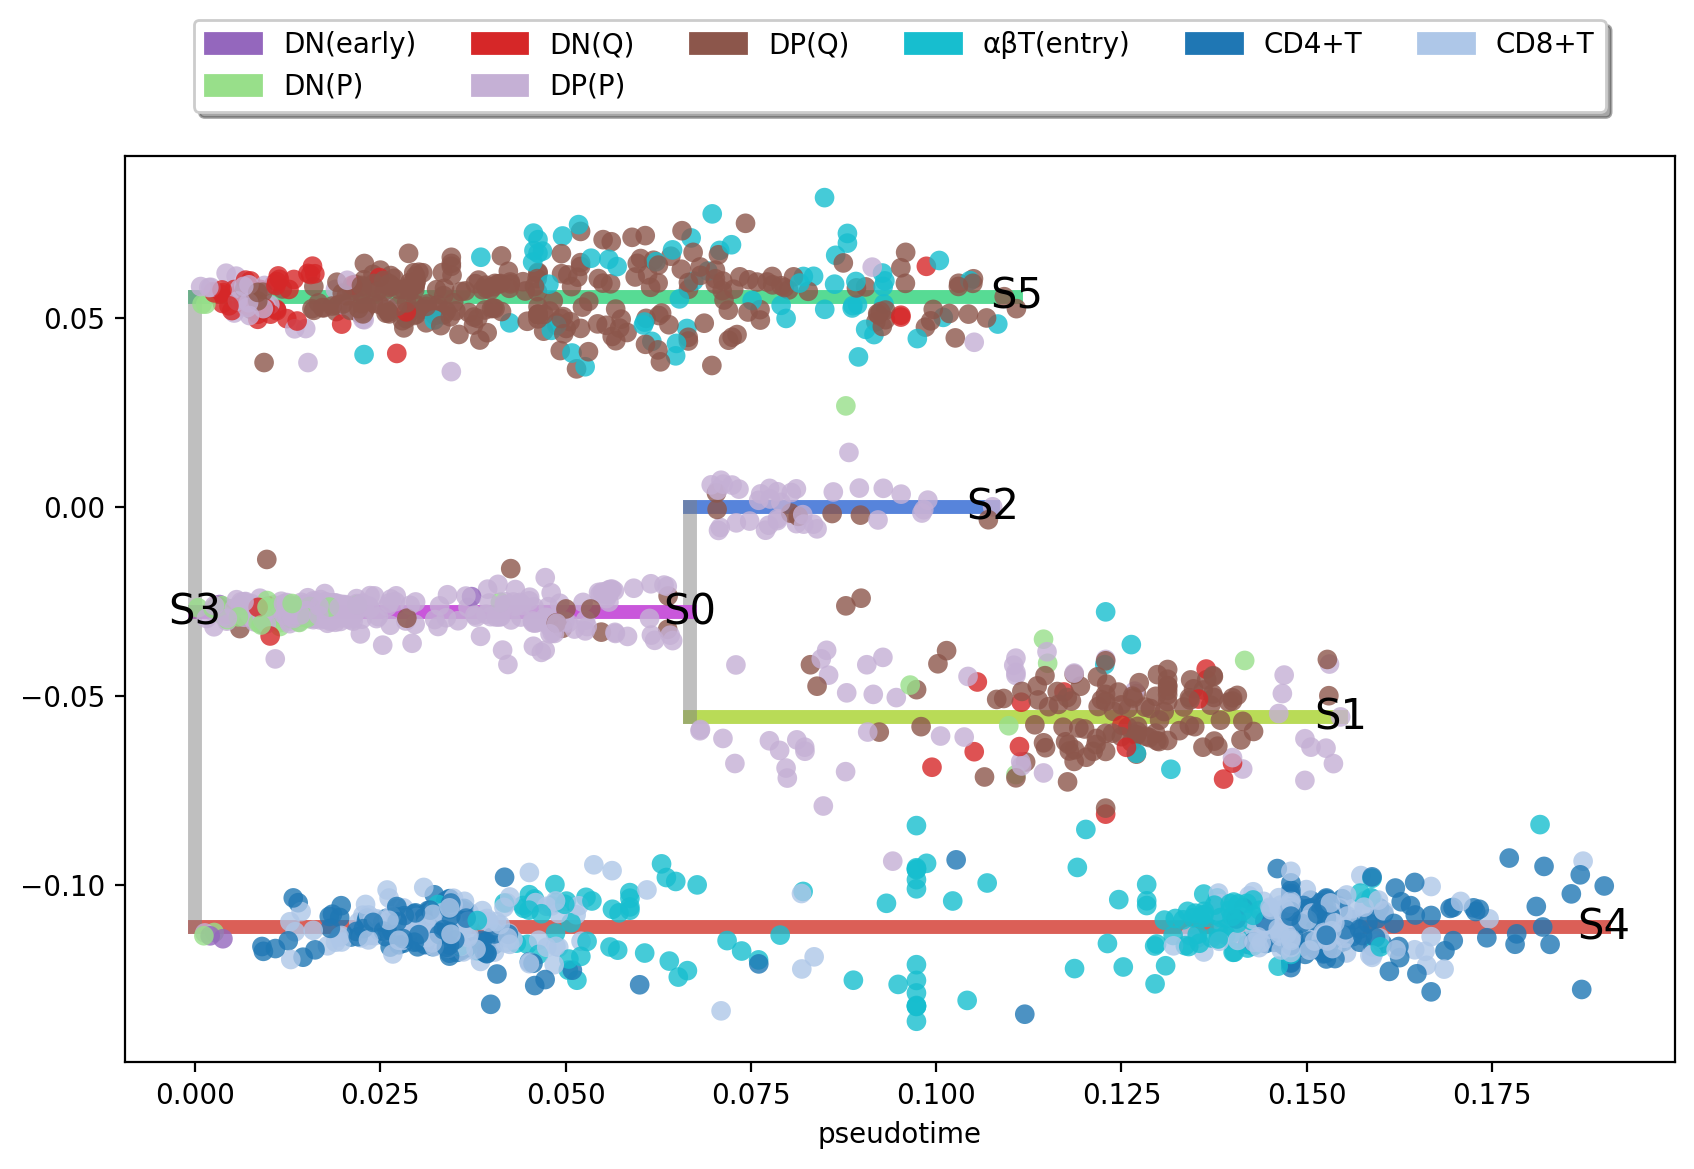

S3 is the designated early root, S0 is predominantly a proliferating DP-associated region, and S1 includes later DP(Q)-associated cells. Hence S3 → S0 → S1 is a **plausible partial maturation** path, but does not end in a differentiated fate. S3 → S5 reaches DP(Q)/αβT(entry)-rich cells, whereas S3 → S4 reaches a mature CD4+/CD8+-rich region.

### 11.1. Fixed points — 17 PCW

In [18]:
# Require the 17 PCW mature-SP-enriched S4 observation to be stable.
s4_target_17 = bo17.fixed(~bo17.obs('S4'))

### 11.2. Positive reachability — 17 PCW

In [19]:
# Early proliferating-to-quiescent DP-associated development 
~bo17.obs('S3') >= ~bo17.obs('S0')
~bo17.obs('S0') >= ~bo17.obs('S1')

# Partial maturation toward DP(Q)/αβT(entry) populations.
~bo17.obs('S3') >= ~bo17.obs('S5')


~bo17.obs('S3') >= s4_target_17

reach('<bonesis.language.ManagedIface.__init__.<locals>.managed.<locals>.Managed object at 0x7c474976e7a0>', '<bonesis.language.ManagedIface.__init__.<locals>.managed.<locals>.Managed object at 0x7c474973e270>')

### 11.3. Original optimization objectives — 17 PCW

In [20]:
bo17.maximize_nodes()
bo17.maximize_strong_constants()
view17 = bonesis.NonStrongConstantNodesView(bo17, mode='opt')
script17 = ctx17['output'] / 'select_components_17w.sh'
view17.standalone(output_filename=str(script17))
print('17 PCW script:', script17)

17 PCW script: ../Results/Component_selection_Tcell_manual/17w/select_components_17w.sh


### 12. Optional: run Clingo separately for each week

By default only the standalone scripts are exported. Run them in WSL/Linux after reviewing these exact constraints. A feasible solution is not necessarily an optimal one: verify `OPTIMUM FOUND` in each log.

In [22]:
import subprocess

for ctx, script in [(ctx12, script12), (ctx17, script17)]:
    log_path = ctx['output'] / 'clingo_optimization.log'
    command = ['bash', str(script), f'--time-limit={OPTIMIZATION_TIME_LIMIT_SECONDS}']
    print(ctx['week'], ' '.join(command), '>', log_path)
    if not RUN_OPTIMIZATION_IN_NOTEBOOK:
        continue
    if shutil.which('bash') is None or shutil.which('clingo') is None:
        raise RuntimeError('Run the exported scripts in your BoNesis/Clingo WSL environment')
    with log_path.open('w') as output:
        subprocess.run(command, stdout=output, stderr=subprocess.STDOUT, check=False)
    txt = log_path.read_text(errors='replace')
    print('OPTIMUM FOUND' if 'OPTIMUM FOUND' in txt else
          'UNSATISFIABLE' if 'UNSATISFIABLE' in txt else
          'Feasible or incomplete: inspect log')

12w bash ../Results/Component_selection_Tcell_manual/12w/select_components_12w.sh --time-limit=14400 > ../Results/Component_selection_Tcell_manual/12w/clingo_optimization.log
OPTIMUM FOUND
17w bash ../Results/Component_selection_Tcell_manual/17w/select_components_17w.sh --time-limit=14400 > ../Results/Component_selection_Tcell_manual/17w/clingo_optimization.log
OPTIMUM FOUND
